# Phase 4 — Prévision de la variance quotidienne

Implémentation d’une fenêtre mobile et d’une EWMA pour estimer la variance de la prochaine séance à partir des rendements antérieurs. L’évaluation des erreurs est présentée en phase 5.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
f = pd.read_csv(ROOT / 'data/forecasts/sp500_forecasts.csv', parse_dates=['target_date', 'forecast_origin'])
valid = f.dropna(subset=['moving_window_variance', 'ewma_variance'])
valid.head()

,target_date,forecast_origin,moving_window_variance,ewma_variance,period
22,2016-10-06,2016-10-05,0.000082,0.000082,training
23,2016-10-07,2016-10-06,0.000082,0.000077,training
24,2016-10-10,2016-10-07,0.000082,0.000073,training
25,2016-10-11,2016-10-10,0.000054,0.000070,training
26,2016-10-12,2016-10-11,0.000051,0.000075,training


## 1. Dates d’origine et dates cibles

L’origine correspond à la dernière séance observée et la cible à la séance prévue. Les valeurs enregistrées sont des variances en unités de rendement décimal au carré.

In [2]:
assert (valid.forecast_origin < valid.target_date).all()
valid[['target_date', 'forecast_origin']].head()

,target_date,forecast_origin
22,2016-10-06,2016-10-05
23,2016-10-07,2016-10-06
24,2016-10-10,2016-10-07
25,2016-10-11,2016-10-10
26,2016-10-12,2016-10-11


## 2. Vérification d’une prévision par fenêtre mobile

La prévision est la moyenne des 21 derniers rendements au carré. Ce second moment approche la variance sous l’hypothèse de moyenne conditionnelle nulle ; il diffère de l’écart-type d’échantillon calculé en phase 2.

In [3]:
returns = pd.read_csv(ROOT / 'data/processed/sp500_phase2.csv', index_col='date', parse_dates=True).log_return
row = valid.loc[valid.target_date >= '2023-01-01'].iloc[0]
history = returns.loc[:row.forecast_origin].tail(21)
manual = (history**2).mean()
print('Target:', row.target_date.date(), 'last input:', history.index[-1].date())
print('Manual:', manual, 'saved:', row.moving_window_variance)
np.testing.assert_allclose(manual, row.moving_window_variance)

Target: 2023-01-03 last input: 2022-12-30
Manual: 0.00012958976787269508 saved: 0.0001295897678726


## 3. Vérification de la récursion EWMA

Le dernier rendement au carré reçoit un poids de 6 %, contre 94 % pour l’estimation précédente. L’initialisation utilise 21 rendements valides consécutifs et est répétée après une lacune.

In [4]:
position = f.index[f.target_date == row.target_date][0]
manual_ewma = .94 * f.loc[position-1, 'ewma_variance'] + .06 * returns.loc[row.forecast_origin]**2
print('Manual:', manual_ewma, 'saved:', row.ewma_variance)
np.testing.assert_allclose(manual_ewma, row.ewma_variance)

Manual: 0.00016951736070868427 saved: 0.0001695173607087


## 4. Prévisions sur la période de validation

Les graphiques affichent la racine carrée des variances prévues, annualisée pour faciliter la lecture. Les valeurs enregistrées restent des variances quotidiennes.

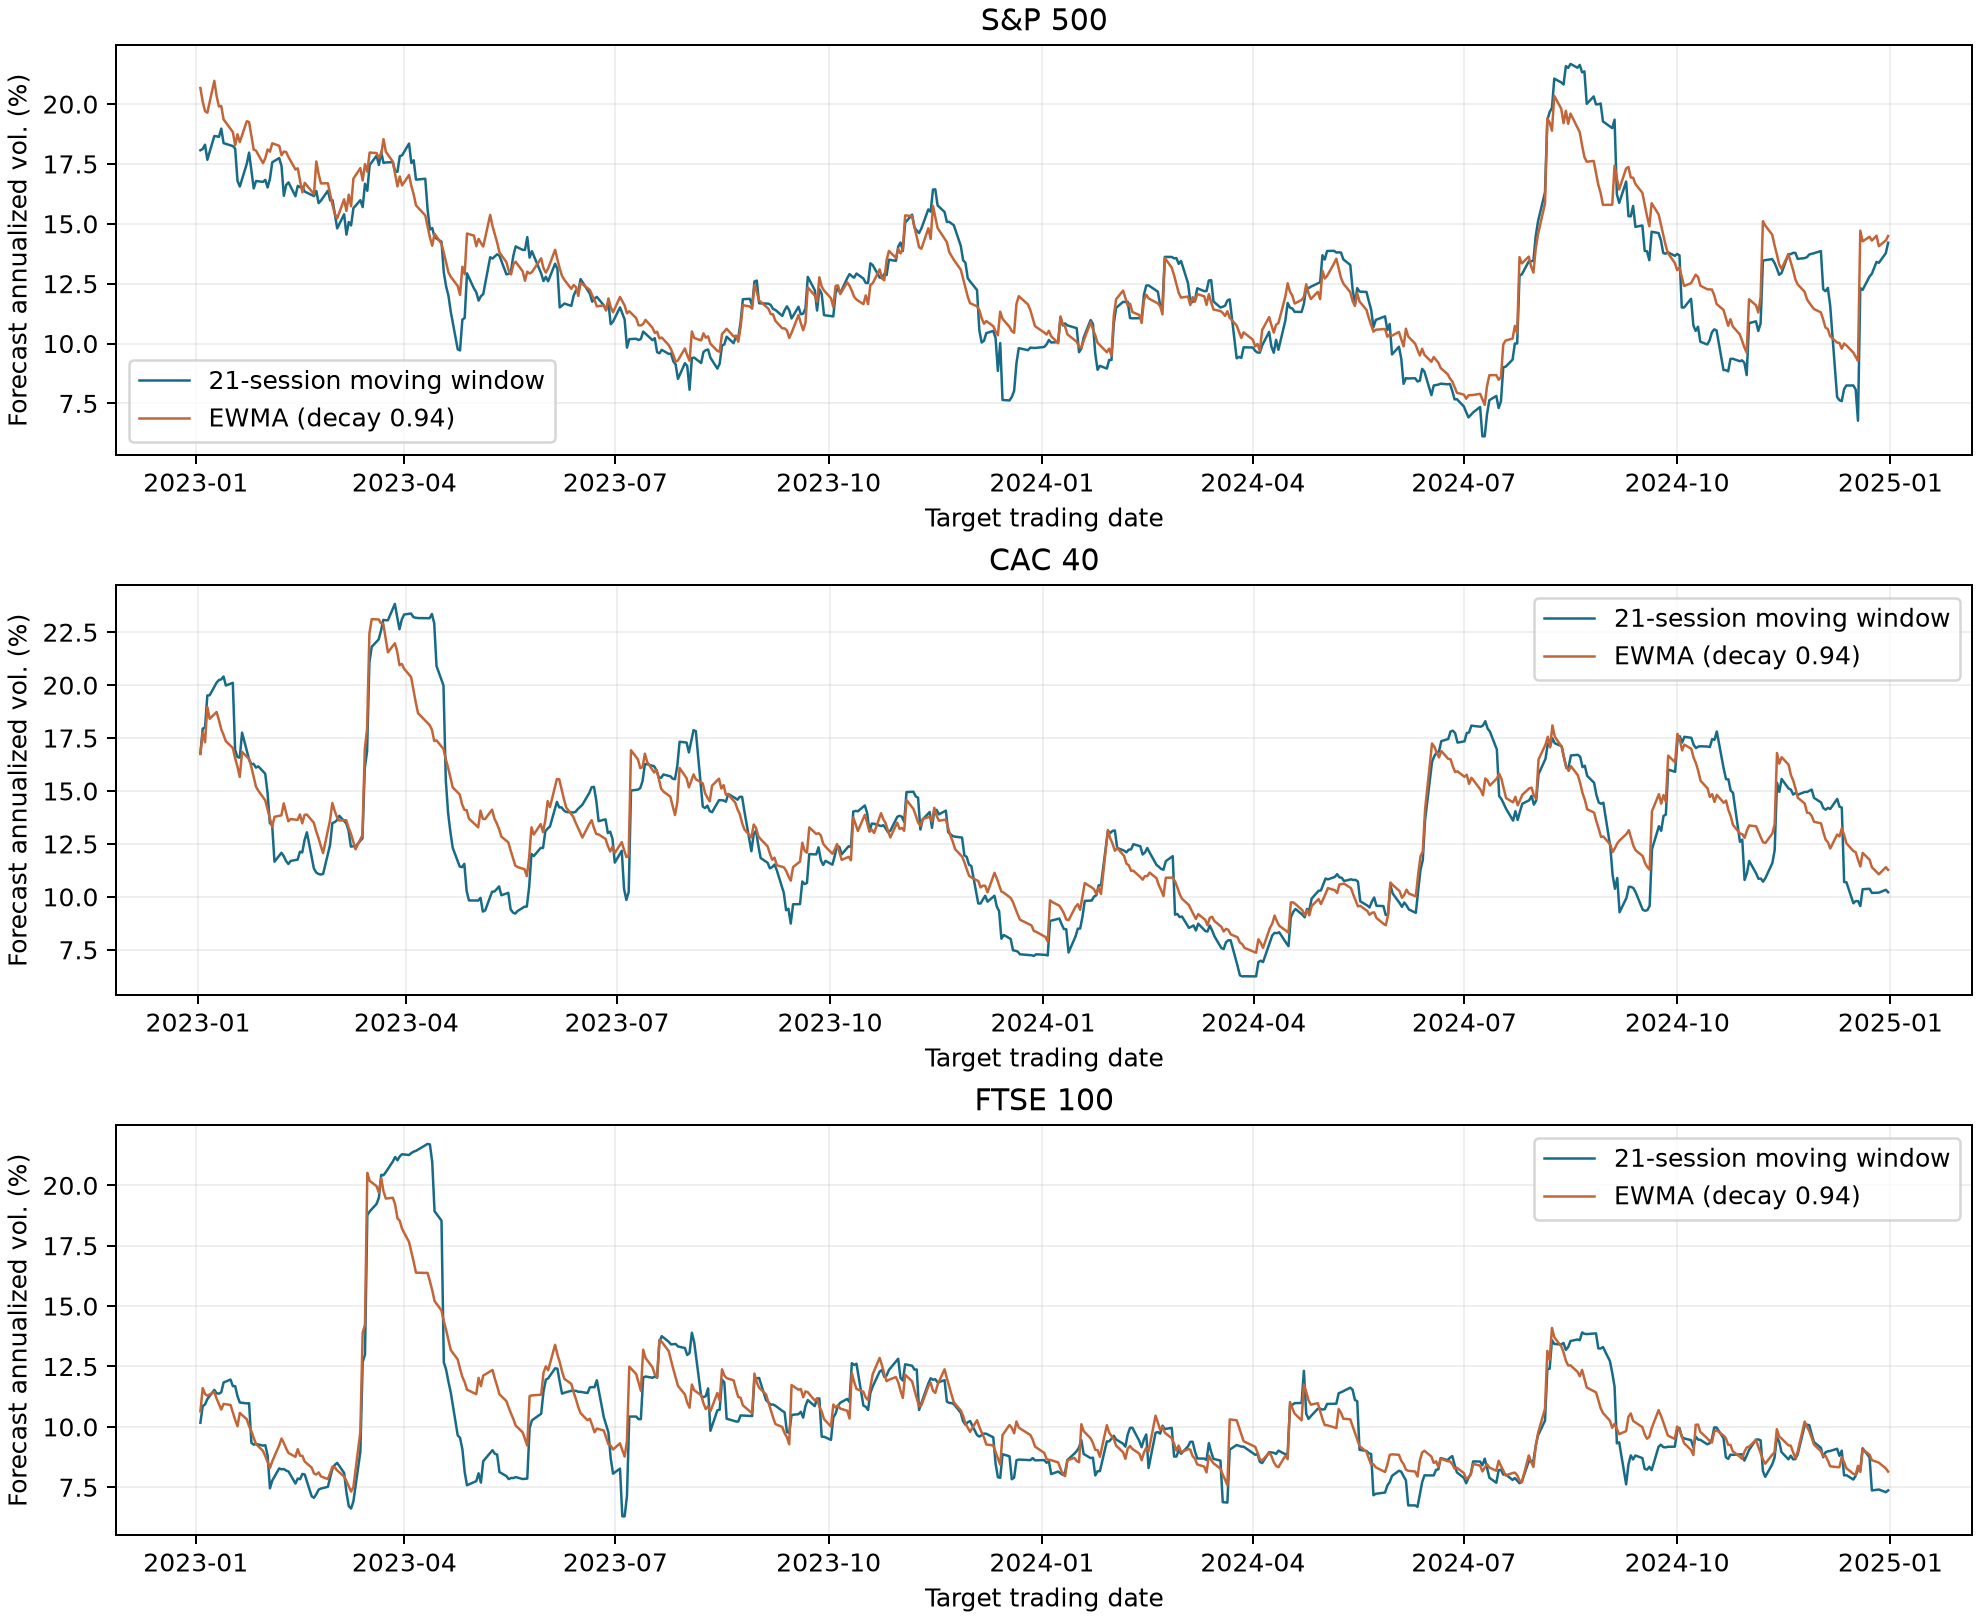

In [5]:
display(Image(filename=str(ROOT / 'reports/figures/phase4_validation_forecasts.png')))

## 5. Traitement de la lacune du FTSE

Une prévision peut être produite avant qu’une cible manquante soit connue. Dès qu’un rendement manquant entre dans l’historique disponible, les deux méthodes sont réinitialisées et attendent 21 rendements valides consécutifs.

In [6]:
ftse = pd.read_csv(ROOT / 'data/forecasts/ftse100_forecasts.csv', index_col='target_date', parse_dates=True)
ftse.loc['2020-12-21':'2021-01-06']

,forecast_origin,moving_window_variance,ewma_variance,period
target_date,,,,
2020-12-21,2020-12-18,0.000066,0.000096,training
2020-12-22,2020-12-21,0.000080,0.000108,training
2020-12-23,2020-12-22,NaN,NaN,training
2020-12-24,2020-12-23,NaN,NaN,training
2020-12-29,2020-12-24,NaN,NaN,training
2020-12-30,2020-12-29,NaN,NaN,training
2020-12-31,2020-12-30,NaN,NaN,training
2021-01-04,2020-12-31,NaN,NaN,training
2021-01-05,2021-01-04,NaN,NaN,training


## 6. Paramètres et couverture

La fenêtre de 21 séances et le facteur EWMA de 0,94 sont fixés a priori. L’historique complet ayant été visualisé auparavant, la période de test n’est pas totalement inédite.

In [7]:
pd.read_csv(ROOT / 'reports/phase4_forecast_coverage.csv')

,index,period,target_rows,available_moving_window,available_ewma
0,S&P 500,training,1592,1570,1570
1,S&P 500,validation,502,502,502
2,S&P 500,test,420,420,420
3,CAC 40,training,1620,1598,1598
4,CAC 40,validation,511,511,511
5,CAC 40,test,428,428,428
6,FTSE 100,training,1597,1553,1553
7,FTSE 100,validation,505,505,505
8,FTSE 100,test,424,424,424


In [8]:
json.loads((ROOT / 'reports/phase4_model_config.json').read_text())

{'window_sessions': 21,
 'ewma_decay': 0.94,
 'selection': 'Fixed educational choices; not optimized using validation or test losses',
 'target': 'Next trading-session variance under a zero conditional-mean approximation',
 'training_end': '2022-12-31',
 'validation_start': '2023-01-01',
 'validation_end': '2024-12-31',
 'test_start': '2025-01-01',
 'test_end': '2026-09-04',
 'missing_policy': 'Reset on missing return; wait for 21 consecutive valid returns',
 'ewma_seed': 'Mean of first 21 consecutive squared returns after start/reset',
 'units': 'Squared decimal log returns',
 'supervisor_agreement': 'Not recorded; proposed protocol implemented at user request',
 'prior_inspection': 'Full-history charts/statistics viewed in earlier phases; later period is not wholly unseen'}